<a href="https://colab.research.google.com/github/Alien-73/Building_Energy_Flex/blob/main/PMV_prediction_Built.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PMV prediction with two pipelines
# **Pipeline#1: 3-step model**
here an ML#1 model predicts the "MET" and then another ML#2 model predicts the "Clo". Then all the data is used to calcualte the PMV with a mathematical equation (M#3)

In [3]:
pip install casadi

In [ ]:
pip install pythermalcomfort

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 kB 872.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.0/362.0 kB 3.6 MB/s eta 0:00:00


In [4]:
#Packages and libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge,Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
import casadi as ca

In [5]:
#importing, preprocessing the dataset

#second Timestamp Age	Gender Weight	Height	Bodyfat	Bodytemp	Sport-Last-Hour	Time-Since-Meal	Tiredness	Clothing-Level	Radiation-Temp	PCE-Ambient-Temp	Air-Velocity	Metabolic-Rate	Emotion-Self	Emotion-ML	Nose	Neck	RShoulder	RElbow	LShoulder	LElbow	REye	LEye	REar	LEar	Wrist_Skin_Temperature	Heart_Rate	GSR	Ambient_Temperature	Ambient_Humidity	Solar_Radiation	Label
#df = pd.read_csv("ASHRAE_extended_2.1.csv")
df = pd.read_csv("Chinese TCD all Classes_subset2.csv")
df["Date"] = pd.to_datetime(df["Date"], errors='coerce')
hour = (
    df["Date"].dt.hour +
    df["Date"].dt.minute / 60 +
    df["Date"].dt.second / 3600
)
# Weekend feature
df["is_weekend"] = (df["Date"].dt.dayofweek >= 5).astype(int)
df["month"] = df["Date"].dt.month
df["hour"] = df["Date"].dt.hour
# Cyclical hour encoding
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
#---------------------
doy = df["Date"].dt.dayofyear

df['doy_sin'] = np.sin(2*np.pi*doy/365)
df['doy_cos'] = np.cos(2*np.pi*doy/365)
#---------------------
#Engineered Features
#df = df.sort_values(["City", "Date"])
df['temp_avg_3'] = df["Indoor Air Temperature"].rolling(window=3, min_periods=1).mean()
df['temp_avg_5'] = df["Indoor Air Temperature"].rolling(window=5, min_periods=1).mean()
df['met_avg_3'] = (
    df.groupby('City')['Metabolic Rate']
      .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)#df['met_avg_5'] = df['Metabolic Rate'].rolling(window=5, min_periods=1).mean()
df['met_EWMA_3'] = (df.groupby("City")['Metabolic Rate'].transform(lambda s: s.shift(1).ewm(span=3, adjust=False).mean()))
df['clo_avg_5'] = df["Clothing Insulation"].transform(lambda s: s.shift(1).rolling(window=5, min_periods=1).mean())
df["clo_avg_3"] = df["Clothing Insulation"].transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
df["Clo_EWMA_5"] = df['Clothing Insulation'].transform(lambda s: s.shift(1).ewm(span=5, adjust=False).mean())
#df["clo_avg_3"] = (df.groupby("City")["Clothing Insulation"].transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean()))
#df["Clo_EWMA_3"] = (df.groupby("City")["Clothing Insulation"].transform(lambda s: s.shift(1).ewm(span=3, adjust=False).mean()))
df['temp_out_EWMA_5'] = (df.groupby("City")["T out mean"].transform(lambda s: s.shift(1).ewm(span=5, adjust=False).mean()))

#instead of df --> df.groupby("Subject_ID")["Clothing Insulation"]
df['Values02'] = df["Metabolic Rate"]*df["RH"]
df['Tin_RH'] = df["Indoor Air Temperature"]*df["RH"]
df['Values03'] = df["Indoor Air Temperature"]/df["RH"]
df['Values04'] = df["Indoor Air Temperature"]/df["Metabolic Rate"]
#OTHER Engineered Features
df['Tin_minus_Tout'] = (df["Indoor Air Temperature"] - df['T out mean'])
df['Tin_Met'] = df["Metabolic Rate"]*df["Indoor Air Temperature"]
#

df = df[["hour_cos","month","month_cos",'doy_cos',"hour_sin","month_sin",'doy_sin',"is_weekend","Indoor Air Temperature","Metabolic Rate","RH","T out mean","Tin_RH","Tin_minus_Tout",'temp_out_EWMA_5' ,"Building Type",'Clothing Insulation',"Clo_EWMA_5","met_EWMA_3","met_avg_3","Tmrt"]] #,"Sex"##"Country",,'temp_out_EWMA_5','temp_out_EWMA_3' T out mean"

#df = df.loc[df['Clothing Insulation'] <= 2.05]

df['Building_Code'] = 0
df.loc[df['Building Type'] == 'Office', 'Building_Code'] = 0
df.loc[df['Building Type'] == 'Classroom', 'Building_Code'] = 0
df.loc[df['Building Type'] == 'Residential', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Dormitory', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Educational', 'Building_Code'] = 2
df.loc[df['Building Type'] == 'Educationnal', 'Building_Code'] = 2
df.loc[df['Building Type'] == 'Living room', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Bedroom', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Rural residence', 'Building_Code'] = 1
df.loc[~df["Building Type"].isin(['Rural residence', 'Bedroom','Living room','Educational','Educationnal','Dormitory','Residential','Classroom','Office']), 'Building_Code'] = 0

#Removing the Building Types that hav econstant MET rate
df = df[df["Building Type"] != 'Educationnal'].copy()#
df = df[df["Building Type"] != 'Educational'].copy()#
df = df[df["Building Type"] != 'Classroom'].copy()#
city_counts = df["Building Type"].value_counts()
print(city_counts)
df = df[["hour_cos","month","month_cos",'doy_cos',"hour_sin","month_sin",'doy_sin',"is_weekend","Indoor Air Temperature","Metabolic Rate","RH","T out mean","Tin_RH","Tin_minus_Tout",'temp_out_EWMA_5' ,"Building_Code",'Clothing Insulation',"Clo_EWMA_5","met_EWMA_3","met_avg_3","Tmrt"]]
df.dropna(inplace=True)

Building Type
Office             15713
Bedroom             4107
Residential         3435
Dormitory           3220
Living room          966
Rural residence       58
Name: count, dtype: int64


/tmp/ipykernel_40670/1966002241.py:5: DtypeWarning: Columns (15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Chinese TCD all Classes_subset2.csv")


In [6]:
df.describe()

,hour_cos,month,month_cos,doy_cos,hour_sin,month_sin,doy_sin,is_weekend,Indoor Air Temperature,Metabolic Rate,...,T out mean,Tin_RH,Tin_minus_Tout,temp_out_EWMA_5,Building_Code,Clothing Insulation,Clo_EWMA_5,met_EWMA_3,met_avg_3,Tmrt
count,21740.000000,21740.000000,2.174000e+04,21740.000000,21740.000000,2.174000e+04,21740.000000,21740.000000,21740.000000,21740.000000,...,21740.000000,21740.000000,21740.000000,21740.000000,21740.000000,21740.000000,21740.000000,21740.000000,21740.000000,21740.000000
mean,-0.295197,6.660028,-4.539739e-02,-0.061554,-0.351575,-8.076797e-02,-0.060158,0.155704,24.472033,1.094747,...,17.531380,1302.831937,6.940653,17.531680,0.370929,0.693355,0.693482,1.094833,1.094808,24.813689
std,0.614166,3.389318,7.291719e-01,0.755126,0.641942,6.780631e-01,0.649941,0.362583,4.747088,0.201085,...,12.989528,588.681057,10.803401,12.885438,0.483065,0.411442,0.370104,0.152008,0.152393,4.899848
min,-1.000000,1.000000,-1.000000e+00,-0.999963,-1.000000,-1.000000e+00,-0.999991,0.000000,6.800000,0.700000,...,-28.000000,132.600000,-12.800000,-25.600000,0.000000,0.040000,0.150000,0.732812,0.700000,6.200000
25%,-0.866025,4.000000,-8.660254e-01,-0.819015,-0.961262,-8.660254e-01,-0.635432,0.000000,21.700000,1.000000,...,10.100000,861.000000,0.700000,10.100000,0.000000,0.380000,0.399198,1.000000,1.000000,21.900000
50%,-0.382683,7.000000,-1.836970e-16,-0.150055,-0.636078,-2.449294e-16,-0.145799,0.000000,24.800000,1.000000,...,22.300000,1327.500000,3.500000,22.448508,0.000000,0.590000,0.600689,1.025001,1.033333,25.000000
75%,0.021815,9.000000,8.660254e-01,0.702527,0.195090,5.000000e-01,0.516062,0.000000,27.500000,1.200000,...,27.000000,1659.050000,9.700000,27.010783,1.000000,0.920000,0.901697,1.200000,1.200000,27.900000
max,1.000000,12.000000,1.000000e+00,1.000000,1.000000,1.000000e+00,0.999991,1.000000,42.200000,2.000000,...,40.500000,3000.000000,52.600000,40.499982,1.000000,3.000000,2.331748,2.000000,2.000000,46.600000


MET error: MSE :0.0182, RMSE :0.1349,MAE :0.0633,R² :0.5500
# of dataset samples inferred:  4348
Accuracy within ±0.1 MET: 0.8176
Accuracy within ±0.05 MET: 0.7171
                mean  count
MET_bin                    
(0.7, 0.9]  0.770035    287
(0.9, 1.1]  0.899052   2744
(1.1, 1.3]  0.816915   1005
(1.3, 1.5]  0.253333     75
(1.5, 1.7]  0.207547    106
(1.7, 1.9]  0.107143     28
(1.9, 2.1]  0.011628     86


/tmp/ipykernel_40670/1478336695.py:59: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(results.groupby("MET_bin")["within_0.1"].agg(["mean", "count"]))


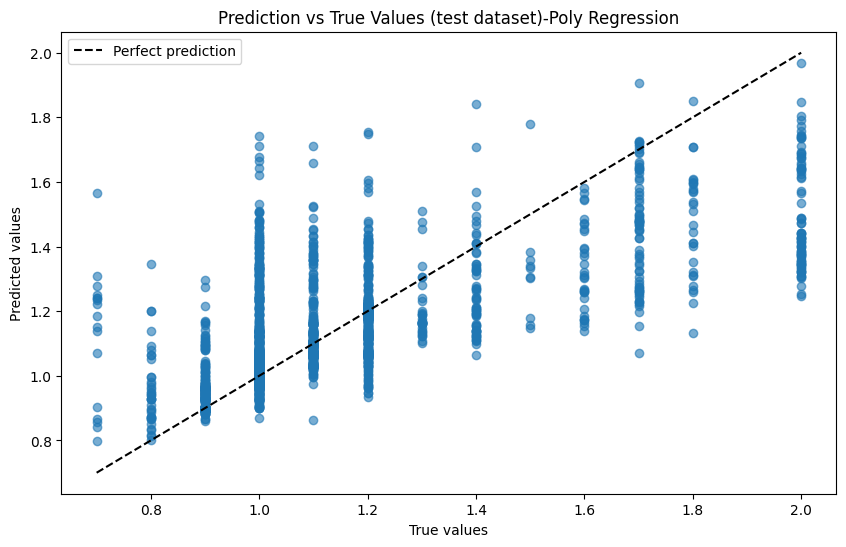

In [10]:
#ML#1- predicting MET
#df = df[["month_cos",'doy_cos',"month_sin",'doy_sin',"is_weekend","Indoor Air Temperature","Metabolic Rate",'met_avg_3','temp_avg_3','temp_avg_5',"RH","Clo-1","Clo_EWMA_3","Clo_EWMA_5","t_out",'Clothing Insulation',"Climate Zone","City", "Country","clo_avg_3",'clo_avg_5',"Tin_Met","Tin_RH","Tin_minus_Tout","Building Type",'temp_out_EWMA_5','temp_out_EWMA_3']]

# Features
#X = df[["doy_sin","doy_cos", "month_cos","is_weekend","Indoor Air Temperature","RH","Tin_RH","t_out"]] #'temp_out_EWMA_3'
#X = df[["hour_cos","doy_cos", "is_weekend","Indoor Air Temperature","Tin_RH","T out mean"]]
#X = df[["Indoor Air Temperature","Tin_RH"]]
#X = df[["doy_cos","doy_sin","is_weekend","Globe Temperature","RH","T out mean","Tin_RH"]]
X_met = df[["hour_sin","doy_cos","month", "is_weekend","T out mean","Indoor Air Temperature","RH","met_avg_3"]] #, "Building_Code", Tin_RH,"Tin_minus_Tout"
#X =  df[["hour_sin", "doy_cos", "doy_sin", "month","is_weekend",'Indoor Air Temperature',"RH","T out mean","Tin_RH","Tin_minus_Tout"]]
#X = df[["hour_cos", "hour_sin", "is_weekend","Metabolic-Rate","Clothing-Level","Ambient_Temperature","Solar_Radiation","Ambient_Humidity"]]

# Target
y_met = df["Metabolic Rate"]

# Optional but recommended:
# scale features so coefficients are comparable
ridge_model_met = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1.0)
)

X_train_met, X_test_met, y_train_met, y_test_met = train_test_split(
    X_met, y_met, test_size=0.2, random_state=42) #, stratify=y


ridge_model_met.fit(X_train_met, y_train_met) #, ridge__sample_weight=sample_weight
y_pred_met = ridge_model_met.predict(X_test_met)

# Metrics
mse = mean_squared_error(y_test_met, y_pred_met)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_met, y_pred_met)
r2 = r2_score(y_test_met, y_pred_met)
#mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # percentage

#PRINTING THE ACCURACY-ERROR
print(f"MET error: MSE :{mse:.4f}, RMSE :{rmse:.4f},MAE :{mae:.4f},R² :{r2:.4f}")
errors = np.abs(y_test_met.values - y_pred_met)

acc_pm01 = (errors <= 0.1).mean()
acc_pm02 = (errors <= 0.05).mean()
print("# of dataset samples inferred: ", len(y_test_met))
print(f"Accuracy within ±0.1 MET: {acc_pm01:.4f}")
print(f"Accuracy within ±0.05 MET: {acc_pm02:.4f}")

import pandas as pd

results = pd.DataFrame({
    "y_true": y_test_met.values,
    "y_pred": y_pred_met,
    "abs_error": errors,
    "within_0.1": errors <= 0.1
})

# bin true values into ranges and check accuracy per bin
results["MET_bin"] = pd.cut(results["y_true"], bins=[0.7, 0.9, 1.1, 1.3, 1.5, 1.7, 1.9, 2.1])
print(results.groupby("MET_bin")["within_0.1"].agg(["mean", "count"]))

#Visulaization _DISABLED
plt.figure(figsize=(10, 6))
plt.title("Prediction vs True Values (test dataset)-Poly Regression")
plt.scatter(y_test_met, y_pred_met, alpha=0.6)

# Perfect prediction line
min_val_met = min(y_test_met.min(), y_pred_met.min())
max_val_met = max(y_test_met.max(), y_pred_met.max())

plt.plot([min_val_met, max_val_met],
         [min_val_met, max_val_met],
         'k--',
         label='Perfect prediction')

plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.legend()
plt.show()

y_pred_met = ridge_model_met.predict(X_met)

# of dataset test samples inferred:  4348
Test results: MSE: 0.0468,RMSE: 0.2164,MAE: 0.1510,R²: 0.7256


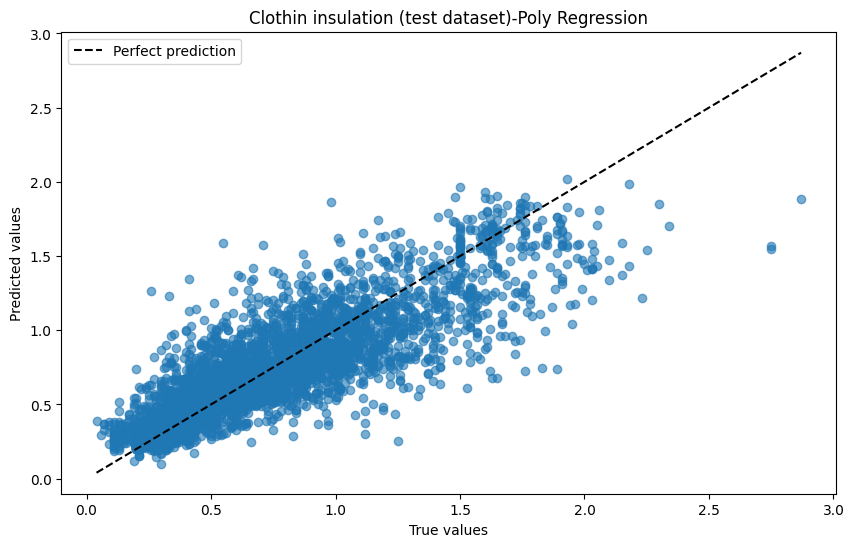

In [19]:
# ML#2-predicting the Clo
#Polynominal Ridge/lasso regression
#all dataset(+classroom+office) - remove clo>2.05 - remove isna
from sklearn.linear_model import ElasticNet, Lasso
#X = df[["month_sin",'doy_sin',"Indoor Air Temperature","Metabolic Rate",,"t_out","RH"]]
X_clo = df[["hour_sin", "doy_cos", "month",  "is_weekend","T out mean", "Indoor Air Temperature", "Tin_RH","Clo_EWMA_5","Metabolic Rate"]] #"temp_out_EWMA_5" "Clo_EWMA_3", #Selected features for Chinease dataset , "Tin_RH", "Building_Code",
# Target
y_clo = df["Clothing Insulation"]
# Optional but recommended:
# scale features so coefficients are comparable

ridge_model_clo = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1.0) #Lasso(alpha=0.1,)#ElasticNet(alpha=1.0, )
)

X_train_clo, X_test_clo, y_train_clo, y_test_clo = train_test_split(
    X_clo,
    y_clo,
    test_size=0.2,
    random_state=42)


ridge_model_clo.fit(X_train_clo, y_train_clo)
y_pred_clo = ridge_model_clo.predict(X_test_clo)

# Metrics
mse = mean_squared_error(y_test_clo, y_pred_clo)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_clo, y_pred_clo)
r2 = r2_score(y_test_clo, y_pred_clo)
#mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # percentage
print("# of dataset test samples inferred: ", len(y_test_clo))
print(f"Test results: MSE: {mse:.4f},RMSE: {rmse:.4f},MAE: {mae:.4f},R²: {r2:.4f}")


plt.figure(figsize=(10, 6))
plt.title("Clothin insulation (test dataset)-Poly Regression")
plt.scatter(y_test_clo, y_pred_clo, alpha=0.6)

# Perfect prediction line
min_val_clo = min(y_test_clo.min(), y_pred_clo.min())
max_val_clo = max(y_test_clo.max(), y_pred_clo.max())

plt.plot([min_val_clo, max_val_clo],
         [min_val_clo, max_val_clo],
         'k--',
         label='Perfect prediction')

plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.legend()
plt.show()

y_pred_clo = ridge_model_clo.predict(X_clo)

In [ ]:
y_pred_clo.shape

(21740,)

In [7]:
#KIKI solution
import casadi as ca

def smax(a, b, eps=1e-4):  return 0.5*(a + b + ca.sqrt((a-b)**2 + eps))
def sabs(a, eps=1e-6):     return ca.sqrt(a**2 + eps)

# --- implicit solve for clothing surface temperature (xn = (t_cl+273)/100) ---
xn  = ca.MX.sym("xn")
par = ca.MX.sym("par", 7)           # ta, tr, vr, icl, fcl, mw, (spare)
ta, tr, vr, icl, fcl, mw = [par[i] for i in range(6)]

taa, tra = ta + 273.0, tr + 273.0
hcf = 12.1*ca.sqrt(vr + 1e-4)
p1  = icl*fcl
p2, p3, p4 = p1*3.96, p1*100, p1*taa
p5  = 308.7 - 0.028*mw + p2*(tra/100)**4

hcn = 2.38*(sabs(100*xn - taa))**0.25
hc  = smax(hcf, hcn)
res = xn*(100 + p3*hc) - (p5 + p4*hc - p2*xn**4)

g = ca.Function("g", [xn, par], [res])
tcl_solver = ca.rootfinder("tcl_solver", "newton", g)

# --- PMV function ---
def pmv_casadi(ta, tr, v, rh, met, clo):
    """ta, tr in °C, v in m/s, rh in %, met in met, clo in clo. Works with MX/SX/DM."""
    M   = met*58.15
    mw  = M                                   # external work = 0
    icl = 0.155*clo
    fcl = ca.if_else(icl <= 0.078, 1 + 1.29*icl, 1.05 + 0.645*icl)
    vr  = v + 0.3*(smax(met, 1.0) - 1.0)      # relative air speed
    pa  = rh*10*ca.exp(16.6536 - 4030.183/(ta + 235))

    par = ca.vertcat(ta, tr, vr, icl, fcl, mw, 0)
    xn0 = (0.5*(ta + 34.0) + 273.0)/100.0     # initial guess
    xn_ = tcl_solver(xn0, par)
    tcl = 100*xn_ - 273.0

    taa, tra = ta + 273.0, tr + 273.0
    hcf = 12.1*ca.sqrt(vr + 1e-4)
    hcn = 2.38*(sabs(tcl - ta))**0.25
    hc  = smax(hcf, hcn)

    hl1 = 3.05e-3*(5733 - 6.99*mw - pa)
    hl2 = 0.42*smax(mw - 58.15, 0.0)
    hl3 = 1.7e-5*M*(5867 - pa)
    hl4 = 1.4e-3*M*(34 - ta)
    hl5 = 3.96*fcl*(xn_**4 - (tra/100)**4)
    hl6 = fcl*hc*(tcl - ta)

    ts = 0.303*ca.exp(-0.036*M) + 0.028
    return ts*(mw - hl1 - hl2 - hl3 - hl4 - hl5 - hl6)

# build a Function
x = ca.MX.sym("x", 6)   # ta, tr, v, rh, met, clo
pmv_f = ca.Function("pmv", [x], [pmv_casadi(*[x[i] for i in range(6)])])
dpmv  = ca.Function("dpmv", [x], [ca.jacobian(pmv_f(x), x)])

In [9]:
from pythermalcomfort.models import pmv_ppd_iso
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
# Calculate PMV and PPD using ISO 7730 standard

PMV_predict = pmv_ppd_iso(
    tdb=df['Indoor Air Temperature'],  #df['Indoor Air Temperature']# Dry Bulb Temperature in °C
    tr=df['Tmrt'], #(df['Indoor Air Temperature']-0.5),  # Mean Radiant Temperature in °C
    vr=0.1,  # Relative air speed in m/s
    rh=df["RH"],  # Relative Humidity in %
    met=y_pred_met ,  # Metabolic rate in met y_pred_met
    clo=y_pred_clo,  # Clothing insulation in clo
    model="7730-2005"  # Year of the ISO standard
)

PMV_true = pmv_ppd_iso(
    tdb=df['Indoor Air Temperature'],  # Dry Bulb Temperature in °C
    tr=df['Tmrt'], #(df['Indoor Air Temperature']-0.5),  # Mean Radiant Temperature in °C
    vr=0.1,  # Relative air speed in m/s
    rh=df["RH"],  # Relative Humidity in %
    met=df['Metabolic Rate'],  # Metabolic rate in met
    clo=df['Clothing Insulation'],  # Clothing insulation in clo
    model="7730-2005"  # Year of the ISO standard
)
df_pmv = pd.DataFrame({'PMV_true_iso':PMV_true.pmv, 'PMV_predict_iso':PMV_predict.pmv})

PMV_true_KIKI = []
PMV_predict_KIKI = []
for i in range(len(df)):
  #float(pmv_f([ta, tr, v, rh, met, clo]))
  PMV_true_KIKI.append(float(pmv_casadi(df['Indoor Air Temperature'].tolist()[i],  df['Tmrt'].tolist()[i], 0.1, df["RH"].tolist()[i], df['Metabolic Rate'].tolist()[i], df['Clothing Insulation'].tolist()[i])))
  PMV_predict_KIKI.append(float(pmv_casadi(df['Indoor Air Temperature'].tolist()[i], df['Tmrt'].tolist()[i], 0.1, df["RH"].tolist()[i], y_pred_met.tolist()[i], y_pred_clo.tolist()[i])))
df_pmv['PMV_true_kiki'] = PMV_true_KIKI
df_pmv['PMV_predict_kiki'] = PMV_predict_KIKI

df_pmv.dropna(inplace=True)
df_pmv.describe()
#print(f"PMV: {PMV_predict.pmv}, PPD: {result.ppd}")
#df_pmv.to_csv("PMV_results.csv", index=False)

/usr/local/lib/python3.13/dist-packages/pythermalcomfort/models/pmv_ppd_iso.py:185: UserWarning: 'tdb' has 2152 values [31.2, 32.3, 30.3, 30.4, 30.3, 30.1, 30.4, 30.7, 30.1, 30.1, 30.1, 30.2, 30.5, 30.1, 30.2, 30.6, 37.2, 30.2, 31.0, 30.6, 30.9, 30.1, 30.4, 30.2, 30.6, 30.3, 33.8, 34.4, 34.0, 33.2, 32.9, 31.4, 31.9, 30.3, 35.0, 34.0, 34.1, 32.4, 33.3, 31.3, 30.1, 30.2, 31.0, 30.7, 31.1, 32.9, 32.7, 31.8, 31.8, 32.4, 32.7, 32.7, 31.2, 33.2, 32.8, 32.8, 32.1, 32.1, 31.9, 30.1, 30.3, 30.2, 31.2, 31.2, 31.3, 31.4, 32.2, 31.6, 31.1, 31.1, 31.8, 31.6, 32.1, 31.3, 32.7, 32.1, 33.2, 33.1, 32.0, 32.3, 32.6, 31.0, 32.4, 32.1, 32.8, 32.4, 31.3, 32.1, 32.8, 32.8, 33.2, 30.7, 30.4, 31.2, 31.6, 31.9, 31.5, 31.4, 32.0, 31.8, 31.2, 32.6, 32.6, 31.6, 32.3, 30.3, 30.2, 34.2, 32.2, 31.7, 31.2, 30.2, 34.5, 34.2, 34.0, 32.4, 31.3, 30.8, 30.1, 31.1, 33.1, 31.0, 33.1, 33.0, 32.6, 34.5, 33.0, 33.2, 34.9, 32.9, 33.9, 33.9, 32.9, 32.0, 33.8, 30.3, 30.9, 30.1, 30.1, 30.9, 30.9, 30.7, 31.7, 32.9, 32.3, 32.9, 33.9

,PMV_true_iso,PMV_predict_iso,PMV_true_kiki,PMV_predict_kiki
count,15179.000000,15179.000000,15179.000000,15179.000000
mean,-0.095954,-0.080276,-0.155793,-0.141076
std,0.779301,0.725423,0.779076,0.725326
min,-2.000000,-2.000000,-2.490204,-2.541888
25%,-0.590000,-0.510000,-0.646921,-0.572333
50%,-0.080000,-0.080000,-0.125805,-0.128773
75%,0.390000,0.340000,0.334519,0.277100
max,1.990000,1.990000,1.986039,1.982589


MSE: 0.1673,RMSE: 0.4090,MAE: 0.3013,R²: 0.7245


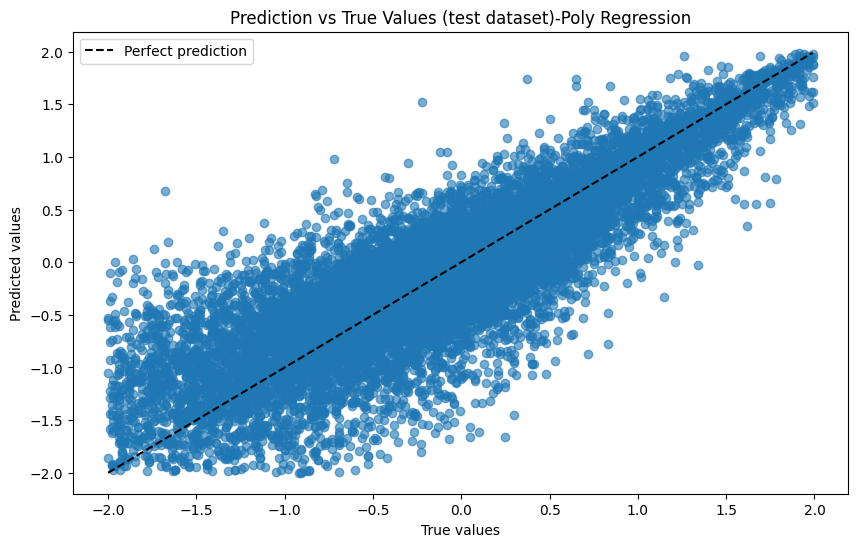

In [10]:
#VISUALS RESULTS and Metrics
# Metrics
mse = mean_squared_error(df_pmv["PMV_true_iso"], df_pmv["PMV_predict_iso"])
rmse = np.sqrt(mse)
mae = mean_absolute_error(df_pmv["PMV_true_iso"], df_pmv["PMV_predict_iso"])
r2 = r2_score(df_pmv["PMV_true_iso"], df_pmv["PMV_predict_iso"])
#mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # percentage
print(f"MSE: {mse:.4f},RMSE: {rmse:.4f},MAE: {mae:.4f},R²: {r2:.4f}")
plt.figure(figsize=(10, 6))
plt.title("Prediction vs True Values (test dataset)-Poly Regression")
plt.scatter(df_pmv["PMV_true_iso"], df_pmv["PMV_predict_iso"], alpha=0.6)

# Perfect prediction line
min_val_pmv = min(df_pmv["PMV_true_iso"].min(), df_pmv["PMV_predict_iso"].min())
max_val_pmv = max(df_pmv["PMV_true_iso"].max(), df_pmv["PMV_predict_iso"].max())

plt.plot([min_val_pmv, max_val_pmv],
         [min_val_pmv, max_val_pmv],
         'k--',
         label='Perfect prediction')

plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.legend()
plt.show()

MSE: 0.1609,RMSE: 0.4011,MAE: 0.2965,R²: 0.7349


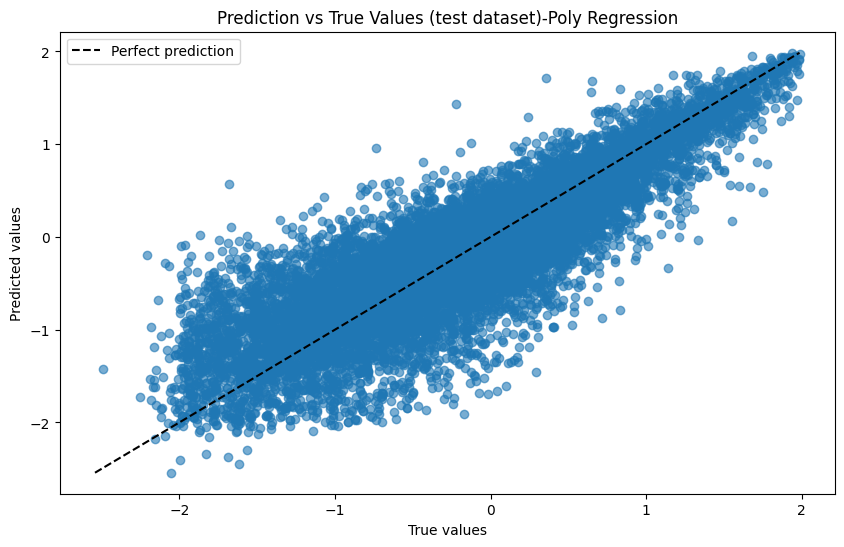

In [11]:
#VISUALS RESULTS and Metrics
# Metrics
mse = mean_squared_error(df_pmv["PMV_true_kiki"], df_pmv["PMV_predict_kiki"])
rmse = np.sqrt(mse)
mae = mean_absolute_error(df_pmv["PMV_true_kiki"], df_pmv["PMV_predict_kiki"])
r2 = r2_score(df_pmv["PMV_true_kiki"], df_pmv["PMV_predict_kiki"])
#mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # percentage
print(f"MSE: {mse:.4f},RMSE: {rmse:.4f},MAE: {mae:.4f},R²: {r2:.4f}")
plt.figure(figsize=(10, 6))
plt.title("Prediction vs True Values (test dataset)-Poly Regression")
plt.scatter(df_pmv["PMV_true_kiki"], df_pmv["PMV_predict_kiki"], alpha=0.6)

# Perfect prediction line
min_val_pmv = min(df_pmv["PMV_true_kiki"].min(), df_pmv["PMV_predict_kiki"].min())
max_val_pmv = max(df_pmv["PMV_true_kiki"].max(), df_pmv["PMV_predict_kiki"].max())

plt.plot([min_val_pmv, max_val_pmv],
         [min_val_pmv, max_val_pmv],
         'k--',
         label='Perfect prediction')

plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.legend()
plt.show()

In [16]:
#FIRST FILE SAVE model
pmv_f.save("pmv.casadi")        # inputs: [ta, tr, v, rh, met, clo], output: PMV

In [14]:
#SECOND FILE: load model
import casadi as ca

pmv_f = ca.Function.load("pmv.casadi")

# numeric call
print(pmv_f([24, 24, 0.1, 50, 1.2, 0.5]))   # should be about -0.5

# symbolic call + derivatives
x = ca.MX.sym("x", 6)
pmv = pmv_f(x)
dpmv_dx = ca.Function("dpmv", [x], [ca.jacobian(pmv, x)])

-0.404101


In [39]:
#MET EXPORT first file
import numpy as np, json

poly   = ridge_model_met.named_steps["polynomialfeatures"]
scaler = ridge_model_met.named_steps["standardscaler"]
ridge  = ridge_model_met.named_steps["ridge"]

np.savez("met_poly.npz",
         powers=poly.powers_,            # (n_terms, n_features) exponents
         mean=scaler.mean_,              # (n_terms,)
         scale=scaler.scale_,            # (n_terms,)
         coef=ridge.coef_.ravel(),       # (n_terms,)
         intercept=np.atleast_1d(ridge.intercept_))

# keep the input order with the model, you will need it in the other file
json.dump(list(X_met.columns), open("met_poly_features.json", "w"))
print(list(X_met.columns))

['hour_sin', 'doy_cos', 'month', 'is_weekend', 'T out mean', 'Indoor Air Temperature', 'RH', 'met_avg_3']


In [40]:
# met_poly_model.py
import numpy as np
import casadi as ca

def load_params(path="met_poly.npz"):
    return dict(np.load(path))

def met_poly_casadi(x, p):
    """x: casadi vector (MX/SX/DM) of the raw features, in training order. Returns MET."""
    powers, mean, scale, coef = p["powers"], p["mean"], p["scale"], p["coef"]
    intercept = float(p["intercept"][0])
    n_feat = powers.shape[1]
    max_pow = int(powers.max())

    # precompute x_i^k once, so each term is just a product of a few cached powers
    xp = [[1.0] + [x[i]**k for k in range(1, max_pow + 1)] for i in range(n_feat)]

    y = intercept
    for t in range(powers.shape[0]):
        term = 1.0
        for i in range(n_feat):
            e = int(powers[t, i])
            if e > 0:
                term = term * xp[i][e]
        y = y + coef[t] * (term - mean[t]) / scale[t]
    return y

def make_met_function(path="met_poly.npz"):
    p = load_params(path)
    x = ca.MX.sym("x", p["powers"].shape[1])
    return ca.Function("met_poly", [x], [met_poly_casadi(x, p)])

In [41]:
met_f = make_met_function("met_poly.npz")

In [42]:
# in the notebook: save a few reference rows
np.savez("met_poly_check.npz", X=X_test_met.iloc[:20].values, y=ridge_model_met.predict(X_test_met.iloc[:20]))

# in the other file
chk = np.load("met_poly_check.npz")
mine = np.array([float(met_f(r)) for r in chk["X"]])
print("max abs diff:", np.abs(mine - chk["y"]))

max abs diff: [6.66133815e-16 7.77156117e-16 4.44089210e-16 2.22044605e-16
 2.22044605e-16 4.44089210e-16 1.33226763e-15 4.44089210e-16
 1.11022302e-16 4.44089210e-16 1.11022302e-16 2.22044605e-16
 4.44089210e-16 2.22044605e-16 6.66133815e-16 2.22044605e-16
 4.44089210e-16 4.44089210e-16 8.88178420e-16 0.00000000e+00]


In [21]:
#CLO EXPORT first file
import numpy as np, json

poly   = ridge_model_clo.named_steps["polynomialfeatures"]
scaler = ridge_model_clo.named_steps["standardscaler"]
ridge  = ridge_model_clo.named_steps["ridge"]

np.savez("clo_poly.npz",
         powers=poly.powers_,            # (n_terms, n_features) exponents
         mean=scaler.mean_,              # (n_terms,)
         scale=scaler.scale_,            # (n_terms,)
         coef=ridge.coef_.ravel(),       # (n_terms,)
         intercept=np.atleast_1d(ridge.intercept_))

# keep the input order with the model, you will need it in the other file
json.dump(list(X_clo.columns), open("clo_poly_features.json", "w"))
print(list(X_clo.columns))

['hour_sin', 'doy_cos', 'month', 'is_weekend', 'T out mean', 'Indoor Air Temperature', 'Tin_RH', 'Clo_EWMA_5', 'Metabolic Rate']


In [27]:
#SECOND FILE CLO
clo_f = make_met_function("clo_poly.npz")

# clo_poly_model.py
import numpy as np
import casadi as ca

def load_params(path="clo_poly.npz"):
    return dict(np.load(path))

def clo_poly_casadi(x, p):
    """x: casadi vector (MX/SX/DM) of the raw features, in training order. Returns Clo."""
    powers, mean, scale, coef = p["powers"], p["mean"], p["scale"], p["coef"]
    intercept = float(p["intercept"][0])
    n_feat = powers.shape[1]
    max_pow = int(powers.max())

    # precompute x_i^k once, so each term is just a product of a few cached powers
    xp = [[1.0] + [x[i]**k for k in range(1, max_pow + 1)] for i in range(n_feat)]

    y = intercept
    for t in range(powers.shape[0]):
        term = 1.0
        for i in range(n_feat):
            e = int(powers[t, i])
            if e > 0:
                term = term * xp[i][e]
        y = y + coef[t] * (term - mean[t]) / scale[t]
    return y

def make_clo_function(path="clo_poly.npz"):
    p = load_params(path)
    x = ca.MX.sym("x", p["powers"].shape[1])
    return ca.Function("clo_poly", [x], [clo_poly_casadi(x, p)])
# pmv_model.py
import casadi as ca

def smax(a, b, eps=1e-4): return 0.5*(a + b + ca.sqrt((a-b)**2 + eps))
def sabs(a, eps=1e-6):    return ca.sqrt(a**2 + eps)

def pmv_casadi(ta, tr, v, rh, met, clo, n_iter=40):
    ...   # paste the function body from my previous message

def make_pmv_function():
    x = ca.MX.sym("x", 6)   # ta, tr, v, rh, met, clo
    return ca.Function("pmv", [x], [pmv_casadi(*[x[i] for i in range(6)])])

In [30]:
hour_sin

MX(opti0_p_3)

In [34]:
met_f, clo_f =  make_met_function(), make_clo_function()
#pmv_f,make_pmv_function(),
opti = ca.Opti()
ta = opti.variable()
met_avg_3 = opti.parameter();
Clo_EWMA_5 = opti.parameter();
rh = opti.parameter(); opti.set_value(rh, 50)
#clo = opti.parameter(); opti.set_value(clo, 0.7)
t_out, hour_sin,  doy_cos, month, weekend = [opti.parameter() for _ in range(5)]
# ... set_value for each of these

tr = ta - 0.5 #OR Tmrt
met_in = ca.vertcat(hour_sin, doy_cos, month, weekend, t_out, ta, rh, met_avg_3)
#met_raw = met_f(met_in)
met = ca.fmin(ca.fmax(met_in, 0.8), 2.0)   # keep inside the range the model was trained on
clo_raw = clo_f(ca.vertcat(hour_sin, doy_cos, month, weekend, t_out, ta, ta*rh,Clo_EWMA_5, met )) #df[["hour_sin", "doy_cos", "month",  "is_weekend","T out mean", "Indoor Air Temperature", "Tin_RH","Clo_EWMA_5","Metabolic Rate"]]
clo = ca.fmin(ca.fmax(clo_raw, 0.0), 2.0)

pmv = pmv_f(ca.vertcat(ta, tr, 0.1, rh, met, clo))
opti.minimize(pmv**2)
opti.subject_to(opti.bounded(16, ta, 30))

RuntimeError: Error in Function::call for 'clo_poly' [MXFunction] at .../casadi/core/function.cpp:532:
.../casadi/core/function_internal.hpp:1791: Input 0 (i0) has mismatching shape. Got 16-by-1. Allowed dimensions, in general, are:
 - The input dimension N-by-M (here 9-by-1)
 - A scalar, i.e. 1-by-1
 - M-by-N if N=1 or M=1 (i.e. a transposed vector)
 - N-by-M1 if K*M1=M for some K (argument repeated horizontally)
 - N-by-P*M, indicating evaluation with multiple arguments (P must be a multiple of 1 for consistency with previous inputs)

# **Pipeline#2: 1-step model**
Here an ML model predicts the "PMV" straight from the inputs fwithout knowing the Clo and Met values.

In [ ]:
pip install casadi

  Using cached casadi-3.8.1-cp311-abi3-manylinux_2_28_x86_64.whl.metadata (2.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 MB 9.4 MB/s eta 0:00:00


In [ ]:
#Packages and libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge,Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
#import casadi as ca

In [ ]:
#importing, preprocessing the dataset

#second Timestamp Age	Gender Weight	Height	Bodyfat	Bodytemp	Sport-Last-Hour	Time-Since-Meal	Tiredness	Clothing-Level	Radiation-Temp	PCE-Ambient-Temp	Air-Velocity	Metabolic-Rate	Emotion-Self	Emotion-ML	Nose	Neck	RShoulder	RElbow	LShoulder	LElbow	REye	LEye	REar	LEar	Wrist_Skin_Temperature	Heart_Rate	GSR	Ambient_Temperature	Ambient_Humidity	Solar_Radiation	Label
#df = pd.read_csv("ASHRAE_extended_2.1.csv")
df = pd.read_csv("Chinese TCD all Classes_subset2.csv")
df["Date"] = pd.to_datetime(df["Date"], errors='coerce')
hour = (
    df["Date"].dt.hour +
    df["Date"].dt.minute / 60 +
    df["Date"].dt.second / 3600
)
# Weekend feature
df["is_weekend"] = (df["Date"].dt.dayofweek >= 5).astype(int)
df["month"] = df["Date"].dt.month
df["hour"] = df["Date"].dt.hour
# Cyclical hour encoding
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
#---------------------
doy = df["Date"].dt.dayofyear

df['doy_sin'] = np.sin(2*np.pi*doy/365)
df['doy_cos'] = np.cos(2*np.pi*doy/365)
#---------------------
#Engineered Features
#df = df.sort_values(["City", "Date"])
df['temp_avg_3'] = df["Indoor Air Temperature"].rolling(window=3, min_periods=1).mean()
df['temp_avg_5'] = df["Indoor Air Temperature"].rolling(window=5, min_periods=1).mean()
df['met_avg_3'] = (
    df.groupby('City')['Metabolic Rate']
      .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)#df['met_avg_5'] = df['Metabolic Rate'].rolling(window=5, min_periods=1).mean()
df['met_EWMA_3'] = (df.groupby("City")['Metabolic Rate'].transform(lambda s: s.shift(1).ewm(span=3, adjust=False).mean()))
df['clo_avg_5'] = df["Clothing Insulation"].transform(lambda s: s.shift(1).rolling(window=5, min_periods=1).mean())
df["clo_avg_3"] = df["Clothing Insulation"].transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean())
df["Clo_EWMA_5"] = df['Clothing Insulation'].transform(lambda s: s.shift(1).ewm(span=5, adjust=False).mean())
#df["clo_avg_3"] = (df.groupby("City")["Clothing Insulation"].transform(lambda s: s.shift(1).rolling(window=3, min_periods=1).mean()))
#df["Clo_EWMA_3"] = (df.groupby("City")["Clothing Insulation"].transform(lambda s: s.shift(1).ewm(span=3, adjust=False).mean()))
df['temp_out_EWMA_5'] = (df.groupby("City")["T out mean"].transform(lambda s: s.shift(1).ewm(span=5, adjust=False).mean()))

#instead of df --> df.groupby("Subject_ID")["Clothing Insulation"]
df['Values02'] = df["Metabolic Rate"]*df["RH"]
df['Tin_RH'] = df["Indoor Air Temperature"]*df["RH"]
df['Values03'] = df["Indoor Air Temperature"]/df["RH"]
df['Values04'] = df["Indoor Air Temperature"]/df["Metabolic Rate"]
#OTHER Engineered Features
df['Tin_minus_Tout'] = (df["Indoor Air Temperature"] - df['T out mean'])
df['Tin_Met'] = df["Metabolic Rate"]*df["Indoor Air Temperature"]
#

df = df[["hour_cos","month","month_cos",'doy_cos',"hour_sin","month_sin",'doy_sin',"is_weekend","Indoor Air Temperature","Metabolic Rate","RH","T out mean","Tin_RH","Tin_minus_Tout",'temp_out_EWMA_5' ,"Building Type",'Clothing Insulation',"Clo_EWMA_5","met_EWMA_3","met_avg_3","PMV"]] #,"Sex"##"Country",,'temp_out_EWMA_5','temp_out_EWMA_3' T out mean"

#df = df.loc[df['Clothing Insulation'] <= 2.05]

df['Building_Code'] = 0
df.loc[df['Building Type'] == 'Office', 'Building_Code'] = 0
df.loc[df['Building Type'] == 'Classroom', 'Building_Code'] = 0
df.loc[df['Building Type'] == 'Residential', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Dormitory', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Educational', 'Building_Code'] = 2
df.loc[df['Building Type'] == 'Educationnal', 'Building_Code'] = 2
df.loc[df['Building Type'] == 'Living room', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Bedroom', 'Building_Code'] = 1
df.loc[df['Building Type'] == 'Rural residence', 'Building_Code'] = 1
df.loc[~df["Building Type"].isin(['Rural residence', 'Bedroom','Living room','Educational','Educationnal','Dormitory','Residential','Classroom','Office']), 'Building_Code'] = 0

#Removing the Building Types that hav econstant MET rate
df = df[df["Building Type"] != 'Educationnal'].copy()#
df = df[df["Building Type"] != 'Educational'].copy()#
df = df[df["Building Type"] != 'Classroom'].copy()#
city_counts = df["Building Type"].value_counts()
print(city_counts)
df = df[["hour_cos","month","month_cos",'doy_cos',"hour_sin","month_sin",'doy_sin',"is_weekend","Indoor Air Temperature","Metabolic Rate","RH","T out mean","Tin_RH","Tin_minus_Tout",'temp_out_EWMA_5' ,"Building_Code",'Clothing Insulation',"Clo_EWMA_5","met_EWMA_3","met_avg_3", "PMV"]]
df.dropna(inplace=True)

/tmp/ipykernel_1552/2134108795.py:5: DtypeWarning: Columns (15,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Chinese TCD all Classes_subset2.csv")


Building Type
Office             15713
Bedroom             4107
Residential         3435
Dormitory           3220
Living room          966
Rural residence       58
Name: count, dtype: int64


MSE: 0.4867,RMSE: 0.6976,MAE: 0.4993,R²: 0.7493


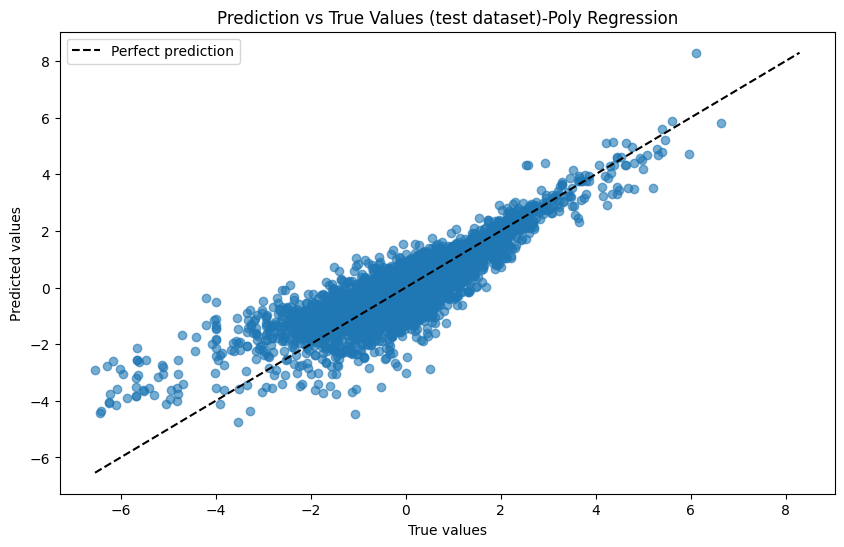

In [ ]:
# ML#2-predicting the PMV directly
#Polynominal Ridge/lasso regression

#X = df[["month_sin",'doy_sin',"Indoor Air Temperature","Metabolic Rate",,"t_out","RH"]]
X_pmv = df[["hour_sin", "doy_cos", "doy_sin", "month","is_weekend",'Indoor Air Temperature',"RH","T out mean","Tin_RH"]] #Selected features for Chinease dataset
# Target
y_pmv = df["PMV"]
# Optional but recommended:
# scale features so coefficients are comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pmv)

# Train linear regression
model = LinearRegression()
model.fit(X_scaled, y_pmv)

# Get coefficients
coefficients = model.coef_
'''
# Plot
fig, ax = plt.subplots(figsize=(6,4))
ax.barh(X.columns,coefficients, align='center')
ax.invert_yaxis()  # labels read top-to-bottom
#plt.yticks(range(len(X.columns)), X.columns)
ax.set_xlabel("Coefficient")
ax.set_ylabel("Features")
ax.grid(True)
plt.title("The Correlation of input data and Clothing Insulation (Clo)")
plt.show()
'''
poly = PolynomialFeatures(
    degree = 3,
    include_bias=False
)
X_poly_pmv = poly.fit_transform(X_pmv)

X_train_pmv, X_test_pmv, y_train_pmv, y_test_pmv = train_test_split(
    X_poly_pmv,
    y_pmv,
    test_size=0.2,
    random_state=42)

ridge_model_pmv = Ridge(alpha=1.0, )#max_iter=None, tol=0.0001,
ridge_model_pmv.fit(X_train_pmv, y_train_pmv)
y_pred_pmv = ridge_model_pmv.predict(X_test_pmv)

# Metrics
mse = mean_squared_error(y_test_pmv, y_pred_pmv)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_pmv, y_pred_pmv)
r2 = r2_score(y_test_pmv, y_pred_pmv)
#mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # percentage
print("# of dataset test samples inferred: ", len(y_test_pmv))
print(f"Test results: MSE: {mse:.4f},RMSE: {rmse:.4f},MAE: {mae:.4f},R²: {r2:.4f}")


plt.figure(figsize=(10, 6))
plt.title("Prediction vs True Values (test dataset)-Poly Regression")
plt.scatter(y_test_pmv, y_pred_pmv, alpha=0.6)

# Perfect prediction line
min_val_pmv = min(y_test_pmv.min(), y_pred_pmv.min())
max_val_pmv = max(y_test_pmv.max(), y_pred_pmv.max())

plt.plot([min_val_pmv, max_val_pmv],
         [min_val_pmv, max_val_pmv],
         'k--',
         label='Perfect prediction')

plt.xlabel("True values")
plt.ylabel("Predicted values")
plt.legend()
plt.show()

y_pred_pmv = ridge_model_met.predict(X_poly_pmv)